# Coelho injection–recovery: Gaussian R versus calibrated IP

This experiment uses the two wavelength regions from `coelho.ipynb`. Region
**8 → calibration order 105** and region **9 → order 104** are explicit choices.
Atmosphere and limb-darkening values are rounded representative posterior
values from that notebook's saved summary; the injected rotation and
macroturbulence are **vsini = 2 km/s** and **zeta = 4 km/s** (`vmacro` in the API).

1. Inspect the IP-only and combined broadening kernels, then generate spectra with a Gaussian IP at **R = 65,000** and the calibrated
   two-Gaussian IP, keeping every stellar parameter and each region's RV identical.
   Compare magnified absorption lines and their flux differences.
2. Add a single realization of independent Gaussian noise, **sigma = 1 / SNR**
   (currently continuum S/N = 200, sigma = 0.005), to the **calibrated-IP** spectrum.
3. Fit that same data with (i) Gaussian R = 65,000 and (ii) the true fixed IP.
   Fit **Teff, logg, [Fe/H], alpha, vsini, zeta, q1, q2, and one RV per region**.
   Both fits have identical stellar priors and marginalized continua, **no GP**,
   and sampled additional jitter with the same default prior. Only the known
   Gaussian measurement noise is injected.

Only the wavelength sampling is reused from the real observation. The synthetic
data contain no tellurics or outliers, so every wavelength pixel is used and no
data-dependent clipping is applied. The injected continuum is unity. This is
an experiment within the same atmosphere grid, not a test of atmosphere-model
systematics. In particular, correct IP does not remove the vsini–zeta degeneracy.

Run in a fresh kernel with this source checkout installed (`pip install -e .`).
Start from the repository root or `examples/specfit`. All inputs are local;
the original notebook, observation, grids, and calibration CSV are read-only.
The notebook displays its figures and saves PDFs and fit bundles to a dedicated
directory under `examples/specfit/results/`, using a new run directory each time.

In [1]:
from pathlib import Path
import os
import sys

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "src/jaxstar/specfit/model.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Run from the jaxstar repository.")
sys.path.insert(0, str(ROOT / "src"))

import numpyro
NUM_CHAINS = 2
numpyro.set_host_device_count(NUM_CHAINS)
import jax
jax.config.update("jax_platform_name", "cpu")
jax.config.update("jax_enable_x64", True)

import hashlib
import json
import shutil
import tempfile
import time
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.signal import find_peaks
from numpyro.diagnostics import summary as sampling_summary
from numpyro.infer import init_to_value
from jaxstar.specfit import (
    Observation, SpecModel, SpecFit, read_ip_calibration,
    single_star_params, make_model_single, save_fit_result,
)

plt.rcParams.update({"figure.dpi": 120, "figure.facecolor": "white", "font.size": 10})
print("JAX:", jax.__version__, "NumPyro:", numpyro.__version__, "devices:", jax.devices())

JAX: 0.11.2 NumPyro: 0.22.0 devices: [CpuDevice(id=0), CpuDevice(id=1)]


## 1. Shared experimental settings and truth

`region_to_ip_order` is the user-supplied correspondence. Change it explicitly
if you choose different regions. `vmacro` denotes zeta in km/s throughout.
The quoted S/N is relative to the normalized continuum; the noise standard
deviation is constant, including inside absorption lines.

The truth values below are deliberately recorded as numbers, so the experiment
does not require a saved real-data posterior or rerun `coelho.ipynb`. Its printed
posterior summary has Teff about 6200 K, logg about 4.15, [Fe/H] about 0.15,
alpha about 0.02, q1/q2 about 0.48, and RVs about -23.12/-23.32 km/s.

In [2]:
grid_dir = ROOT / "examples/specfit/coelho"
data_path = grid_dir / "sample_data_ird.csv"
ip_path = grid_dir / "sample_ip_parameters.csv"
regions = [8, 9]  # zero-based row indices in the observed CSV
region_to_ip_order = {8: 105, 9: 104}
ip_orders = [region_to_ip_order[region] for region in regions]

R_GAUSSIAN = 65_000.0
SNR = 200.0
NOISE_SEED = 20261014
MODEL_PIXELS = 5000
VMAX = 50.0  # km/s
SVI_STEPS = 2000
NUM_WARMUP = 500
NUM_SAMPLES = 500  # per chain, for each of the two models
MAX_PREDICT_DRAWS = 80
SHOW_PROGRESS = True

truth = dict(teff=6200., logg=4.15, feh=.15, alpha=.02,
             vsini=2., vmacro=4., q1=.48, q2=.48,
             rv=np.array([-23.12, -23.32]))
atmosphere_names = ("teff", "logg", "feh", "alpha")
truth_atmosphere = {name: truth[name] for name in atmosphere_names}
truth_broadening = {name: truth[name] for name in ("vsini", "vmacro", "q1", "q2")}

output_parent = ROOT / "examples/specfit/results/ip_comparison"
output_parent.mkdir(parents=True, exist_ok=True)
run_dir = Path(tempfile.mkdtemp(prefix="run_", dir=output_parent))
def show_and_save(fig, filename):
    fig.savefig(run_dir / filename, bbox_inches="tight")
    plt.show()
    plt.close(fig)

display(pd.Series({k: v for k, v in truth.items() if k != "rv"}, name="truth").to_frame())
display(pd.DataFrame({"region": regions, "IP order": ip_orders, "true RV [km/s]": truth["rv"]}))
print("Output:", run_dir)

,truth
teff,6200.00
logg,4.15
feh,0.15
alpha,0.02
vsini,2.00
vmacro,4.00
q1,0.48
q2,0.48


,region,IP order,true RV [km/s]
0,8,105,-23.12
1,9,104,-23.32


Output: /Users/k_masuda/Dropbox/repos/jaxstar/examples/specfit/results/ip_comparison/run_q2o_gxwc


## 2. Wavelengths, fixed calibration, and common atmosphere grid

The public reader expects `directory/parameters.csv`. To leave the supplied
`sample_ip_parameters.csv` unchanged, copy it into a temporary directory under
that standard name, read it, then discard the temporary copy. Only the medians
of the five IP parameters enter the fixed model. `fraction2` is the integrated
weight of component 2. The IP centroid is **not** removed.

Both physical models share the exact same prepared atmosphere grid, velocity
sampling, and kernel support. The original real flux, error bars, and masks do
not enter this synthetic experiment.

In [3]:
observed_table = pd.read_csv(data_path)
wavelength = observed_table["lam"].to_numpy().reshape(-1, 2048)[regions].copy() * 10.
assert np.all(np.isfinite(wavelength)) and np.all(np.diff(wavelength, axis=1) > 0)

with tempfile.TemporaryDirectory(prefix="jaxstar-ip-calibration-") as directory:
    shutil.copyfile(ip_path, Path(directory) / "parameters.csv")
    ip_calibration = read_ip_calibration(directory, orders=ip_orders)

gaussian_specmodel = SpecModel.from_grid(
    grid_dir, wavelength, regions=regions, pattern="*_normed.npz",
    pixels=MODEL_PIXELS, vmax=VMAX, flux_kind="normalized",
)
spectra = gaussian_specmodel.spectra
fixed_specmodel = SpecModel(spectra, vmax=VMAX, fixed_ip=ip_calibration.median)

ip_table = pd.DataFrame(dict(ip_calibration.median), index=pd.Index(regions, name="region"))
ip_table.insert(0, "IP order", ip_orders)
ip_table["centroid_kms"] = ((1 - ip_table.fraction2) * ip_table.mu1_kms
                            + ip_table.fraction2 * ip_table.mu2_kms)
display(ip_table)
display(pd.DataFrame({name: [float(spectra.grid.axis(name)[0]),
                            float(spectra.grid.axis(name)[-1])]
                      for name in atmosphere_names}, index=["lower", "upper"]).T)
print("Model dv [km/s]:", np.diff(np.asarray(fixed_specmodel.velocity_grid), axis=1)[:, 0])

,IP order,mu1_kms,mu2_kms,sigma1_kms,sigma2_kms,fraction2,centroid_kms
region,,,,,,,
8,105,-1.344954,0.839987,1.108959,1.367920,0.627344,0.025756
9,104,-1.073642,1.166887,1.172793,1.111615,0.464416,-0.033104


,lower,upper
teff,3500.0,7000.0
logg,1.0,5.0
feh,-1.0,0.5
alpha,0.0,0.4


Model dv [km/s]: [0.82075586 0.81989219]


## 3. IP-only and combined broadening kernels

Compare the kernels before applying them to an atmosphere spectrum. Each region
has an **IP-only** panel and an **IP + rotation + macroturbulence** panel using
the injected vsini, zeta, and limb darkening. Both cases call the same
`combined_kernel` function used by `SpecModel`; IP-only sets vsini and zeta to
zero. The fixed IP retains both calibrated shifts and the component-2 fraction.

All kernels have unit area. We display the normalized convolution weights
divided by the velocity spacing, so the vertical units are s/km. Smooth lines
use eight-times-finer velocity sampling over the same support; dots show the
actual fitting-grid kernels. Lower panels show **fixed IP minus Gaussian R**.
The common velocity zero is before the separate stellar Doppler shift; the
calibrated IP centroid is retained, with positive shifts toward the red.


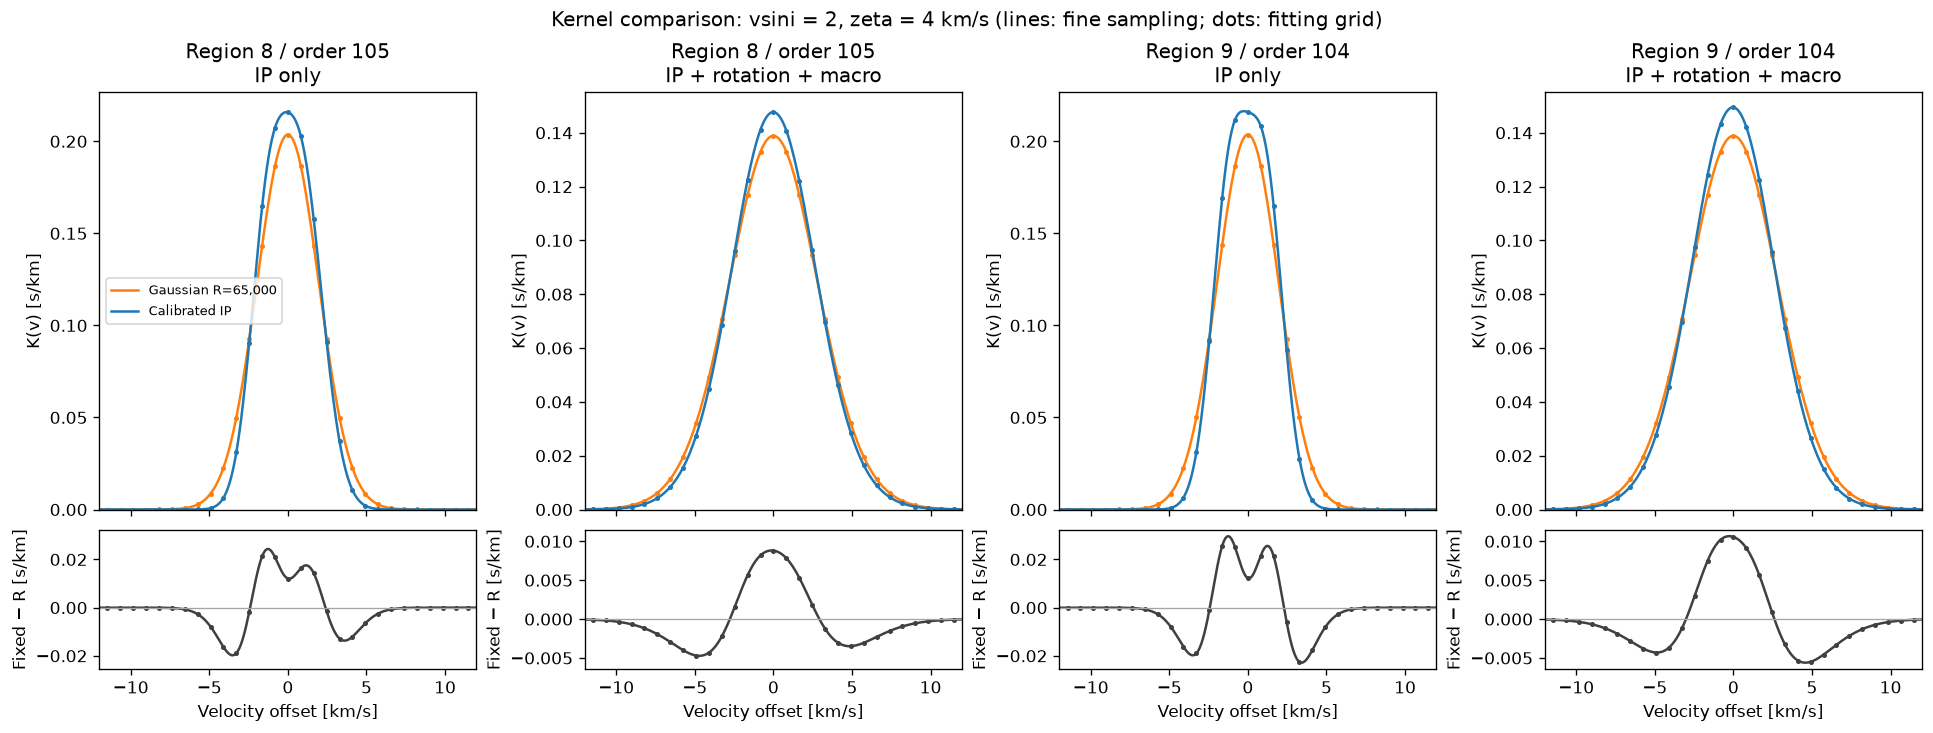

In [4]:
from jaxstar.specfit.broadening import (
    combined_kernel, double_gaussian_fourier, gaussian_sigma,
)

kernel_broadening = single_star_params(
    truth_atmosphere, **truth_broadening, rv=truth["rv"],
)["components"][0]["broadening"]
kernel_colors = {"Gaussian R=65,000": "tab:orange", "Calibrated IP": "tab:blue"}
ip_values = fixed_specmodel.fixed_ip

def kernel_densities(velocity, region_index, *, ip_only):
    """Use the model's kernel implementation, with unit-area density units."""
    ip_fourier = double_gaussian_fourier(
        velocity, **{name: values[region_index] for name, values in ip_values.items()},
    )
    broadening = dict(
        vmacro=0. if ip_only else kernel_broadening["vmacro"],
        vsini=0. if ip_only else kernel_broadening["vsini"],
        u1=kernel_broadening["u1"], u2=kernel_broadening["u2"],
    )
    weights = {
        "Gaussian R=65,000": combined_kernel(
            velocity, **broadening, beta=gaussian_sigma(R_GAUSSIAN)),
        "Calibrated IP": combined_kernel(
            velocity, **broadening, beta=0., ip_fourier=ip_fourier),
    }
    dv = np.mean(np.diff(np.asarray(velocity)))
    for kernel in weights.values():
        np.testing.assert_allclose(np.sum(kernel), 1., atol=1e-12)
    return {name: np.asarray(kernel) / dv for name, kernel in weights.items()}

kernel_comparison = {}
fig, axes = plt.subplots(
    2, 2*len(regions), figsize=(8*len(regions), 6), sharex=True,
    gridspec_kw={"height_ratios": [3, 1]}, layout="constrained",
)
for i, region in enumerate(regions):
    velocity = np.asarray(fixed_specmodel.velocity_grid[i])
    dense_velocity = np.linspace(velocity[0], velocity[-1], 8*(len(velocity)-1) + 1)
    kernel_comparison[region] = {"velocity": velocity, "dense_velocity": dense_velocity}
    for j, (kind, ip_only) in enumerate([
        ("IP only", True), ("IP + rotation + macro", False),
    ]):
        sampled = kernel_densities(velocity, i, ip_only=ip_only)
        dense = kernel_densities(dense_velocity, i, ip_only=ip_only)
        kernel_comparison[region][kind] = {"sampled": sampled, "dense": dense}
        ax, difference = axes[:, 2*i + j]
        if i:
            ax.sharey(axes[0, j])
            difference.sharey(axes[1, j])
        for name, color in kernel_colors.items():
            ax.plot(dense_velocity, dense[name], color=color, lw=1.5, label=name)
            ax.plot(velocity, sampled[name], ".", color=color, ms=4)
        ax.set(title=f"Region {region} / order {ip_orders[i]}\n{kind}",
               ylabel="K(v) [s/km]", ylim=(0, None))
        difference.plot(dense_velocity,
                        dense["Calibrated IP"] - dense["Gaussian R=65,000"], color="0.25")
        difference.plot(velocity,
                        sampled["Calibrated IP"] - sampled["Gaussian R=65,000"],
                        ".", ms=4, color="0.25")
        difference.axhline(0, color="0.65", lw=.8)
        difference.set(xlabel="Velocity offset [km/s]", ylabel="Fixed − R [s/km]",
                       xlim=(-12, 12))
axes[0, 0].legend(fontsize=8)
fig.suptitle(f"Kernel comparison: vsini = {truth['vsini']:g}, zeta = {truth['vmacro']:g} km/s"
             " (lines: fine sampling; dots: fitting grid)", fontsize=12)
show_and_save(fig, "kernel_comparison.pdf")


## 4. Noiseless spectra at identical stellar RV

The two calls below differ only in instrumental profile. In particular, they
use the same `rv` vector. The calibrated IP's own shifts may still change line
centroids, as expected. Smooth display curves use a denser output wavelength
array; this does not change the common internal model grid.

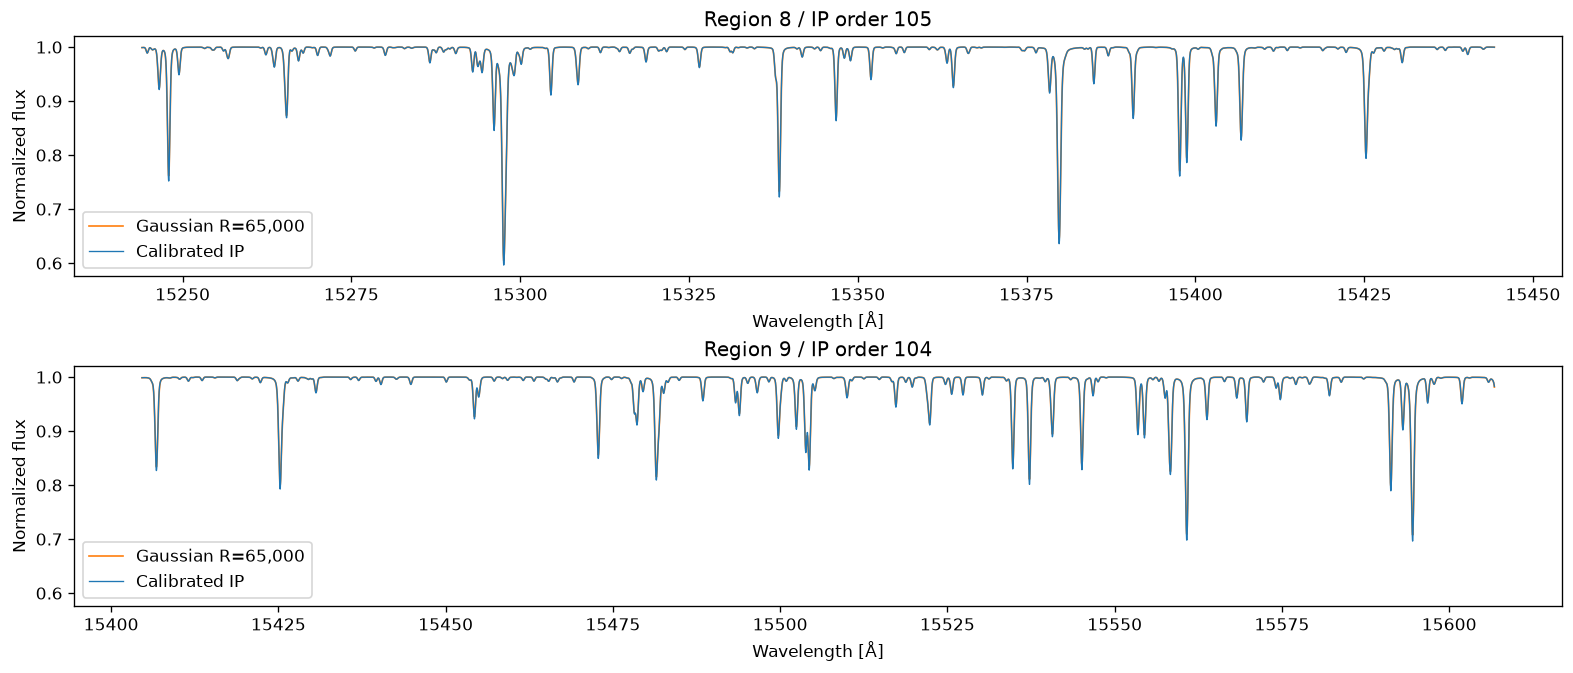

,region,max |fixed - Gaussian|,RMS(fixed - Gaussian)
0,8,0.009682,0.001017
1,9,0.011341,0.001282


In [5]:
fixed_truth_params = single_star_params(truth_atmosphere, **truth_broadening, rv=truth["rv"])
gaussian_truth_params = single_star_params(
    truth_atmosphere, **truth_broadening, rv=truth["rv"], resolving_power=R_GAUSSIAN,
)
flux_fixed = np.asarray(fixed_specmodel(fixed_truth_params, wavelength))
flux_gaussian = np.asarray(gaussian_specmodel(gaussian_truth_params, wavelength))
wave_dense = np.stack([np.linspace(w[0], w[-1], 8192) for w in wavelength])
fixed_dense = np.asarray(fixed_specmodel(fixed_truth_params, wave_dense))
gaussian_dense = np.asarray(gaussian_specmodel(gaussian_truth_params, wave_dense))

fig, axes = plt.subplots(2, 1, figsize=(13, 5.5), sharey=True, layout="constrained")
for i, ax in enumerate(axes):
    ax.plot(wave_dense[i], gaussian_dense[i], label="Gaussian R=65,000", lw=1, color="tab:orange")
    ax.plot(wave_dense[i], fixed_dense[i], label="Calibrated IP", lw=.8, color="tab:blue")
    ax.set(title=f"Region {regions[i]} / IP order {ip_orders[i]}",
           xlabel="Wavelength [Å]", ylabel="Normalized flux")
    ax.legend(loc="lower left")
show_and_save(fig, "noiseless_full.pdf")

display(pd.DataFrame({"region": regions,
    "max |fixed - Gaussian|": np.max(np.abs(flux_fixed - flux_gaussian), axis=1),
    "RMS(fixed - Gaussian)": np.sqrt(np.mean((flux_fixed - flux_gaussian)**2, axis=1))}))

,line 1 [Å],line 2 [Å]
8,15297.594447,15379.817371
9,15560.787672,15594.522328


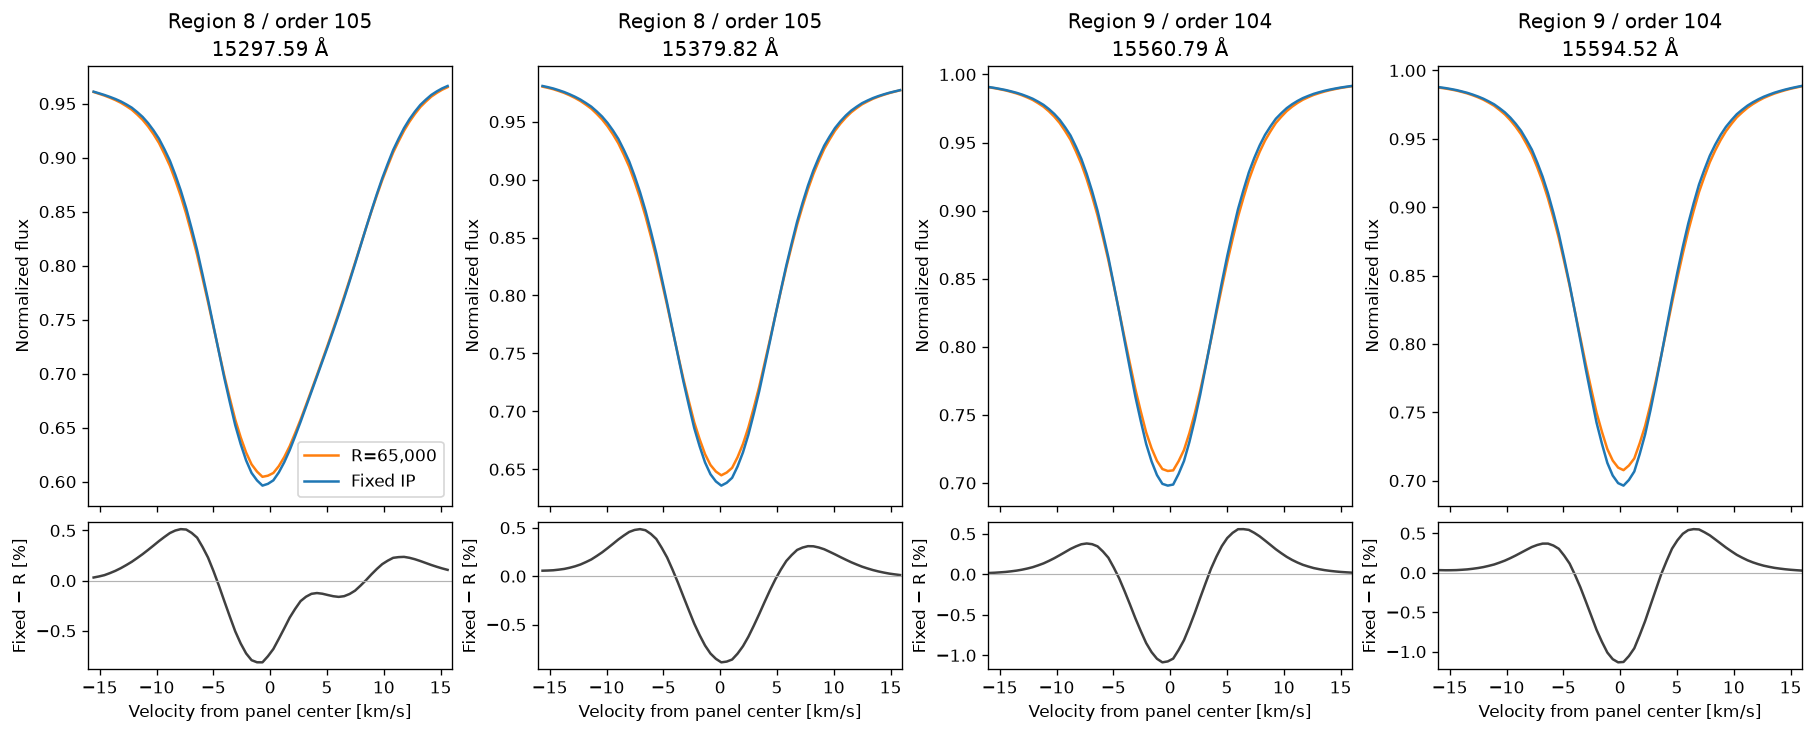

In [6]:
# Choose two deep, separated lines per region using only the noiseless truth.
# Override these wavelengths manually if another transition is of interest.
C_KMS = 299792.458
ZOOM_KMS = 16.
zoom_centers = []
for i in range(len(regions)):
    peaks, info = find_peaks(1 - flux_fixed[i], prominence=.035, distance=50)
    margin = C_KMS * np.minimum(np.log(wavelength[i, peaks] / wavelength[i, 0]),
                                np.log(wavelength[i, -1] / wavelength[i, peaks]))
    peaks = peaks[margin > ZOOM_KMS + 2]
    if len(peaks) < 2:
        raise ValueError("Choose two interior line wavelengths for this region manually.")
    chosen = peaks[np.argsort(flux_fixed[i, peaks])[:2]]
    zoom_centers.append(np.sort(wavelength[i, chosen]))
zoom_centers = np.asarray(zoom_centers)
display(pd.DataFrame(zoom_centers, index=regions, columns=["line 1 [Å]", "line 2 [Å]"]))

fig, axes = plt.subplots(2, 4, figsize=(15, 6), sharex="col",
                         gridspec_kw={"height_ratios": [3, 1]}, layout="constrained")
for i in range(2):
    for j in range(2):
        column = 2*i + j
        velocity = C_KMS * np.log(wave_dense[i] / zoom_centers[i, j])
        keep = np.abs(velocity) <= ZOOM_KMS
        ax, residual = axes[:, column]
        ax.plot(velocity[keep], gaussian_dense[i, keep], color="tab:orange", label="R=65,000")
        ax.plot(velocity[keep], fixed_dense[i, keep], color="tab:blue", label="Fixed IP")
        ax.set(title=f"Region {regions[i]} / order {ip_orders[i]}\n{zoom_centers[i, j]:.2f} Å",
               ylabel="Normalized flux", xlim=(-ZOOM_KMS, ZOOM_KMS))
        residual.plot(velocity[keep], 100*(fixed_dense - gaussian_dense)[i, keep], color="0.25")
        residual.axhline(0, color="0.7", lw=.7)
        residual.set(xlabel="Velocity from panel center [km/s]", ylabel="Fixed − R [%]")
axes[0, 0].legend()
show_and_save(fig, "noiseless_line_zoom.pdf")

## 5. One synthetic observation, S/N = 200

Generate noise **once** from a seeded generator and reuse the same `Observation`
for both fits. The input uncertainty is exactly the injected sigma,
`1 / SNR` (currently 0.005).
The synthetic continuum is one; no GP realization or extra jitter is added.

In [7]:
rng = np.random.default_rng(NOISE_SEED)
sigma = 1. / SNR
noise = rng.normal(0., sigma, wavelength.shape)
flux_observed = flux_fixed + noise
obs = Observation(wavelength, flux_observed, np.full_like(wavelength, sigma), region=regions)
fits = {"Gaussian R=65000": SpecFit(obs, gaussian_specmodel),
        "Correct fixed IP": SpecFit(obs, fixed_specmodel)}
assert fits["Gaussian R=65000"].observation is fits["Correct fixed IP"].observation

np.savez(run_dir / "injection.npz", wavelength=wavelength, flux_observed=flux_observed,
         uncertainty=obs.uncertainty, noise=noise, flux_fixed=flux_fixed,
         flux_gaussian=flux_gaussian, regions=regions, ip_orders=ip_orders)
print("Pixels:", obs.shape, "sigma:", sigma, "noise RMS:", np.sqrt(np.mean(noise**2)))

Pixels: (2, 2048) sigma: 0.005 noise RMS: 0.004978815229614364


## 6. Identical priors and nuisance treatment

All four atmosphere parameters are inferred. As in the original notebook,
use uniform grid priors and the temperature-dependent physical logg ceiling.
Choose explicit, identical RV and vsini bounds rather than CCF-derived bounds:
RV is Uniform(-30, -15) km/s in each region, vsini is Uniform(0, 12), and zeta
is Uniform(1, 15) km/s. q1/q2 each have Uniform(0, 1) priors. Both fits marginalize
the same degree-4 Chebyshev continuum with the package's default coefficient
scales. Jitter is sampled with the same default prior in both fits; GP is
disabled. The IP choice is the only difference between the two likelihood
models.

In [8]:
common_settings = dict(
    rv_bounds=(-30., -15.), vsini_max=12., vmacro_bounds=(1., 15.),
    #fixed={"jitter": 0.}, 
    use_gp=False, use_physical_logg_max=True,
    use_empirical_vmic=False, use_empirical_vmacro=False, degree=4,
)
models = {
    "Gaussian R=65000": make_model_single(fits["Gaussian R=65000"],
                                         resolving_power=R_GAUSSIAN, **common_settings),
    "Correct fixed IP": make_model_single(fits["Correct fixed IP"], **common_settings),
}
for name, model in models.items():
    print(name)
    display(model.check_prior())

initial = dict(teff=6000., logg=4.2, feh=.1, alpha=.05,
               vsini=4., vmacro=5., q1=.5, q2=.5, rv=np.array([-23., -23.]))
for fit in fits.values():
    assert np.all(fit.rv_bounds[:, 0] < -30.) and np.all(fit.rv_bounds[:, 1] > -15.)

Gaussian R=65000


,prior
parameter,
teff,"Uniform(4500, 7000)"
logg | teff,"Uniform(logg_min, physical_logg_max(teff))"
feh,"Uniform(-1, 0.5)"
alpha,"Uniform(0, 0.4)"
vsini,"Uniform(0, 12)"
vmacro,"Uniform(1, 15)"
q1,"Uniform(0, 1)"
q2,"Uniform(0, 1)"
rv,"Uniform([-30, -30], [-15, -15]) [shape=(2,)]"


Correct fixed IP


,prior
parameter,
teff,"Uniform(4500, 7000)"
logg | teff,"Uniform(logg_min, physical_logg_max(teff))"
feh,"Uniform(-1, 0.5)"
alpha,"Uniform(0, 0.4)"
vsini,"Uniform(0, 12)"
vmacro,"Uniform(1, 15)"
q1,"Uniform(0, 1)"
q2,"Uniform(0, 1)"
rv,"Uniform([-30, -30], [-15, -15]) [shape=(2,)]"


## 7. SVI initialization and NUTS for both IP assumptions

Use the same initial guess and computational budget for both models. SVI supplies
only initialization, not the reported uncertainty. NUTS samples all stellar
parameters jointly; compare its posterior quantiles with the injection truth.
`SHOW_PROGRESS` controls the SVI and NUTS progress bars.
Two chains run in parallel; the two IP models are fitted in sequence.
Each model's fit bundle is saved immediately after sampling, before plotting.

In [9]:
points, mcmcs, samples, sampling_diagnostics = {}, {}, {}, {}
for index, (name, fit) in enumerate(fits.items()):
    start = time.perf_counter()
    model = models[name]
    points[name] = fit.run_svi(
        model=model, rng_key=jax.random.PRNGKey(100 + index),
        p_initial=initial, num_steps=SVI_STEPS, step_size=.05, progress_bar=SHOW_PROGRESS,
    )
    mcmcs[name] = fit.run_nuts(
        model=model, rng_key=jax.random.PRNGKey(200 + index),
        num_warmup=NUM_WARMUP, num_samples=NUM_SAMPLES, num_chains=NUM_CHAINS,
        progress_bar=SHOW_PROGRESS, mcmc_kwargs={"chain_method": "parallel"},
        nuts_kwargs={"init_strategy": init_to_value(values=points[name]),
                     "target_accept_prob": .95, "dense_mass": True, "max_tree_depth": 6},
    )
    samples[name] = mcmcs[name].get_samples()
    elapsed = time.perf_counter() - start
    print(f"{name}: {elapsed:.1f} s")
    mcmcs[name].print_summary(exclude_deterministic=True)
    bundle = run_dir / ("gaussian_R65000" if index == 0 else "correct_fixed_ip")
    save_fit_result(bundle, sf=fit, model=model, point=points[name], mcmc=mcmcs[name],
                    metadata={"experiment": "coelho_ip_comparison", "truth": truth,
                              "snr": SNR, "noise_seed": NOISE_SEED,
                              "region_to_ip_order": {str(k): v for k, v in region_to_ip_order.items()},
                              "calibration_csv": str(ip_path),
                              "calibration_sha256": hashlib.sha256(ip_path.read_bytes()).hexdigest()})
    diagnostic = sampling_summary({k: np.asarray(v) for k, v in
        mcmcs[name].get_samples(group_by_chain=True).items() if k in truth}, prob=.68)
    sampling_diagnostics[name] = dict(
        elapsed_seconds=elapsed,
        divergences=int(np.sum(mcmcs[name].get_extra_fields()["diverging"])),
        max_rhat=max(float(np.max(d["r_hat"])) for d in diagnostic.values()),
        min_n_eff=min(float(np.min(d["n_eff"])) for d in diagnostic.values()),
    )
display(pd.DataFrame(sampling_diagnostics).T)

100%|██████████| 2000/2000 [00:21<00:00, 92.53it/s, init loss: -8949.0013, avg. loss [1901-2000]: -15831.7430] 


  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

Gaussian R=65000: 39.2 s

                mean       std    median      5.0%     95.0%     n_eff     r_hat
     alpha      0.02      0.01      0.02      0.02      0.03    531.40      1.00
       feh      0.15      0.01      0.15      0.14      0.16    543.84      1.00
    jitter      0.00      0.00      0.00      0.00      0.00    703.75      1.00
      logg      4.14      0.02      4.14      4.10      4.16    509.72      1.00
        q1      0.54      0.28      0.55      0.14      1.00    612.99      1.00
        q2      0.51      0.30      0.50      0.00      0.91    464.38      1.00
     rv[0]    -23.09      0.02    -23.09    -23.12    -23.06   1050.19      1.00
     rv[1]    -23.37      0.02    -23.37    -23.40    -23.34   1339.85      1.00
      teff   6194.74     12.77   6194.59   6173.36   6214.72    505.16      1.00
    vmacro      3.57      0.28      3.66      3.16      3.93    267.55      1.00
     vsini      1.12      0.72      1.06      0.03      2.15    213.70      1.00

N

100%|██████████| 2000/2000 [00:19<00:00, 104.20it/s, init loss: -10233.2058, avg. loss [1901-2000]: -15833.2654]


  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

Correct fixed IP: 27.0 s

                mean       std    median      5.0%     95.0%     n_eff     r_hat
     alpha      0.03      0.01      0.03      0.02      0.04    292.90      1.01
       feh      0.15      0.01      0.15      0.14      0.16    450.64      1.00
    jitter      0.00      0.00      0.00      0.00      0.00    755.81      1.00
      logg      4.14      0.02      4.14      4.10      4.17    490.66      1.00
        q1      0.51      0.27      0.52      0.07      0.94    537.55      1.00
        q2      0.52      0.28      0.54      0.11      0.98    556.67      1.00
     rv[0]    -23.11      0.02    -23.11    -23.14    -23.08   1684.20      1.00
     rv[1]    -23.34      0.02    -23.34    -23.37    -23.31   2089.85      1.00
      teff   6194.35     13.82   6194.15   6169.85   6215.83    507.45      1.00
    vmacro      4.12      0.32      4.19      3.68      4.57    133.49      1.02
     vsini      1.42      0.80      1.49      0.01      2.48    108.14      1.03

N

,elapsed_seconds,divergences,max_rhat,min_n_eff
Gaussian R=65000,39.185300,0.0,1.004278,213.699279
Correct fixed IP,26.980438,0.0,1.030750,108.141922


## 8. Recovery table and corner comparison

Intervals below are the 16th–84th percentiles; `bias` is posterior median minus
truth for this one noise realization. It is not an ensemble bias estimate.
The table includes all four atmosphere parameters, vsini, zeta, q1/q2, and
both RVs. The overlaid corner plot below shows the six stellar parameters
used in `coelho.ipynb`; q1/q2 and RVs are summarized in the table.


In [10]:
parameter_items = [(name, None, float(truth[name])) for name in
                   ("teff", "logg", "feh", "alpha", "vsini", "vmacro", "q1", "q2")]
parameter_items += [("rv", i, float(truth["rv"][i])) for i in range(len(regions))]
def parameter_label(name, index):
    return f"rv_region{regions[index]}" if index is not None else name
def draws_for(sample, name, index):
    values = np.asarray(sample[name])
    return values if index is None else values[:, index]

records = []
for model_name, sample in samples.items():
    for parameter, index, true_value in parameter_items:
        low, median, high = np.quantile(draws_for(sample, parameter, index), [.16, .5, .84])
        records.append(dict(model=model_name, parameter=parameter_label(parameter, index),
                            truth=true_value, p16=low, median=median, p84=high,
                            bias=median - true_value, truth_in_68pct=(low <= true_value <= high)))
recovery = pd.DataFrame(records).set_index(["parameter", "model"])
display(recovery.round(5))
recovery.to_csv(run_dir / "parameter_recovery.csv")

colors = {"Gaussian R=65000": "tab:orange", "Correct fixed IP": "tab:blue"}


,,truth,p16,median,p84,bias,truth_in_68pct
parameter,model,,,,,,
teff,Gaussian R=65000,6200.00,6181.61014,6194.58596,6207.59682,-5.41404,True
logg,Gaussian R=65000,4.15,4.11740,4.13528,4.15441,-0.01472,True
feh,Gaussian R=65000,0.15,0.14260,0.14839,0.15422,-0.00161,True
alpha,Gaussian R=65000,0.02,0.01904,0.02476,0.03031,0.00476,True
vsini,Gaussian R=65000,2.00,0.32405,1.05845,1.94361,-0.94155,False
vmacro,Gaussian R=65000,4.00,3.27788,3.66345,3.81007,-0.33655,False
q1,Gaussian R=65000,0.48,0.21556,0.54520,0.85121,0.06520,True
q2,Gaussian R=65000,0.48,0.14822,0.50403,0.85788,0.02403,True
rv_region8,Gaussian R=65000,-23.12,-23.11024,-23.09243,-23.07352,0.02757,False


### Overlaid corner plot

Use the same six stellar parameters selected in `coelho.ipynb`: Teff, logg,
[Fe/H], alpha, vsini, and zeta. Orange is the Gaussian R=65,000 posterior and
blue is the correct fixed-IP posterior. The two distributions share bin ranges
and axes; diagonal histograms are normalized densities. Contours enclose 68%
and 95% of each two-dimensional marginal. Black lines mark the injected values,
passed explicitly through `corner.corner(..., truths=corner_truths)`.


In [17]:
truth

{'teff': 6200.0,
 'logg': 4.15,
 'feh': 0.15,
 'alpha': 0.02,
 'vsini': 2.0,
 'vmacro': 4.0,
 'q1': 0.48,
 'q2': 0.48,
 'rv': array([-23.12, -23.32])}

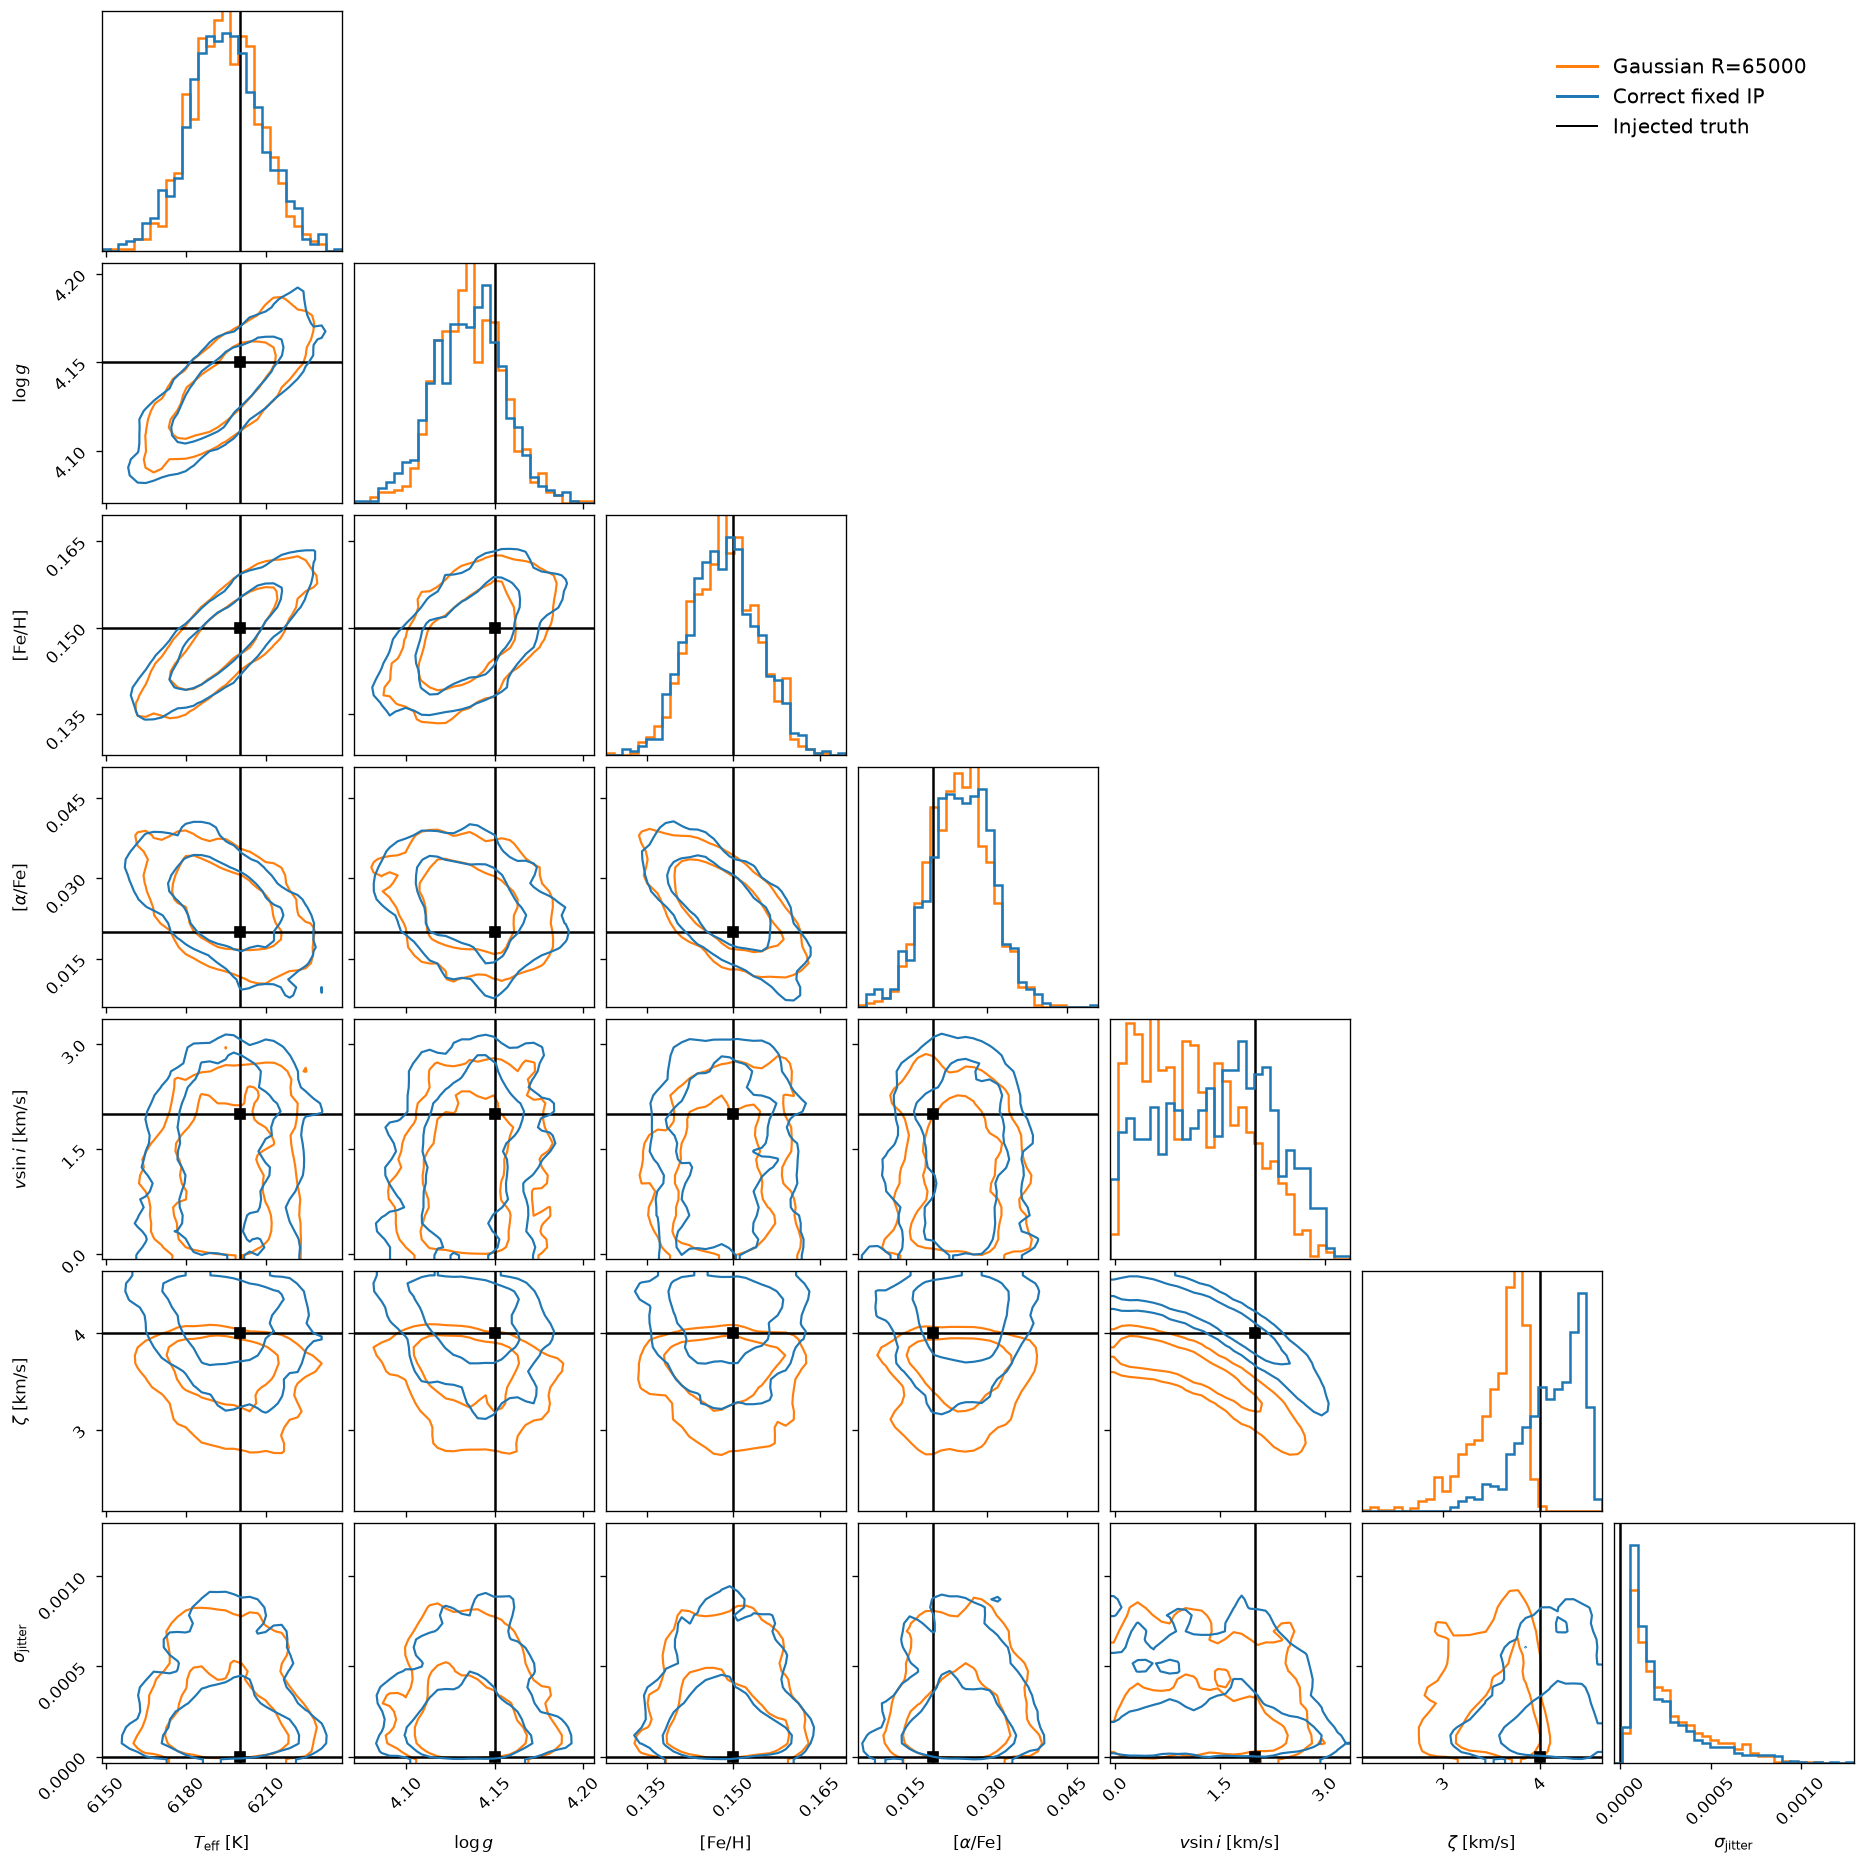

In [18]:
import corner
from matplotlib.lines import Line2D

corner_vars = ["teff", "logg", "feh", "alpha", "vsini", "vmacro", "jitter"]
corner_labels = [r"$T_{\rm eff}$ [K]", r"$\log g$", "[Fe/H]", r"$[\alpha/\mathrm{Fe}]$",
                 r"$v\sin i$ [km/s]", r"$\zeta$ [km/s]", r"$\sigma_\mathrm{jitter}$"]
corner_truths = np.array([float(truth[name]) if name != 'jitter' else 0 for name in corner_vars])
corner_samples = {
    name: np.column_stack([np.asarray(sample[var]).reshape(-1) for var in corner_vars])
    for name, sample in samples.items()
}
# Use the same bins/limits for both posteriors, including every injected value.
combined = np.vstack([*corner_samples.values(), corner_truths[None, :]])
lower, upper = combined.min(axis=0), combined.max(axis=0)
padding = .03 * (upper - lower)
corner_ranges = list(zip(lower - padding, upper + padding))

fig = None
for name, values in corner_samples.items():
    fig = corner.corner(
        values, fig=fig, labels=corner_labels, range=corner_ranges,
        color=colors[name], bins=30, smooth=1., levels=(.68, .95),
        plot_datapoints=False, plot_density=False, fill_contours=False,
        no_fill_contours=True, show_titles=False, max_n_ticks=3,
        hist_kwargs={"density": True, "linewidth": 1.5},
        contour_kwargs={"linewidths": 1.3},
        truths=corner_truths if fig is None else None, truth_color="black",
    )
fig.legend(
    handles=[Line2D([], [], color=colors[name], lw=1.8, label=name)
             for name in corner_samples]
            + [Line2D([], [], color="black", lw=1.2, label="Injected truth")],
    loc="upper right", bbox_to_anchor=(.96, .96), frameon=False, fontsize=12,
)
show_and_save(fig, "corner_overlay.pdf")


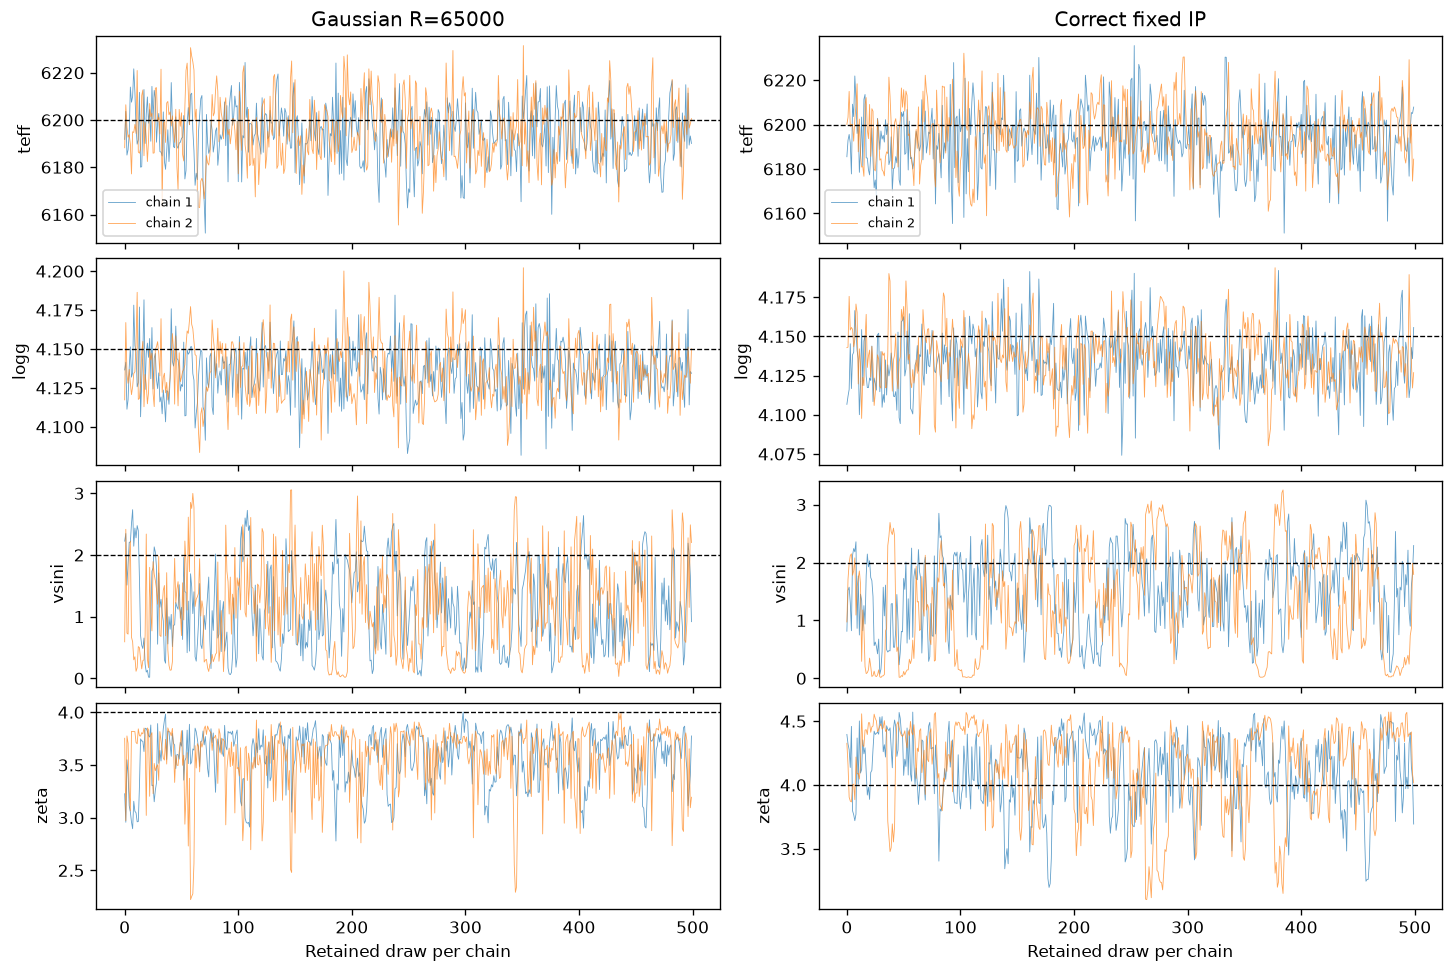

In [13]:
# Check chain mixing; the corner plot above shows the broadening degeneracy.
trace_items = ("teff", "logg", "vsini", "vmacro")
fig, axes = plt.subplots(4, 2, figsize=(12, 8), sharex=True, layout="constrained")
for column, (name, mcmc) in enumerate(mcmcs.items()):
    chains = mcmc.get_samples(group_by_chain=True)
    for row, parameter in enumerate(trace_items):
        ax = axes[row, column]
        for chain in range(NUM_CHAINS):
            ax.plot(chains[parameter][chain], lw=.5, alpha=.7, label=f"chain {chain+1}")
        ax.axhline(truth[parameter], color="black", ls="--", lw=.8)
        ax.set(ylabel=parameter.replace("vmacro", "zeta"))
        if row == 0:
            ax.set_title(name)
            ax.legend(fontsize=8)
        if row == 3:
            ax.set_xlabel("Retained draw per chain")
show_and_save(fig, "trace_comparison.pdf")

## 9. Fitted spectra and residuals for the same noisy data

For each model, average conditional continuum-corrected predictions over the
same number of evenly spaced posterior draws. The shaded interval describes
variation of those conditional mean spectra; it excludes fresh measurement
noise and within-draw continuum uncertainty. Residuals use the known
injected sigma, `1 / SNR` (currently 0.005).

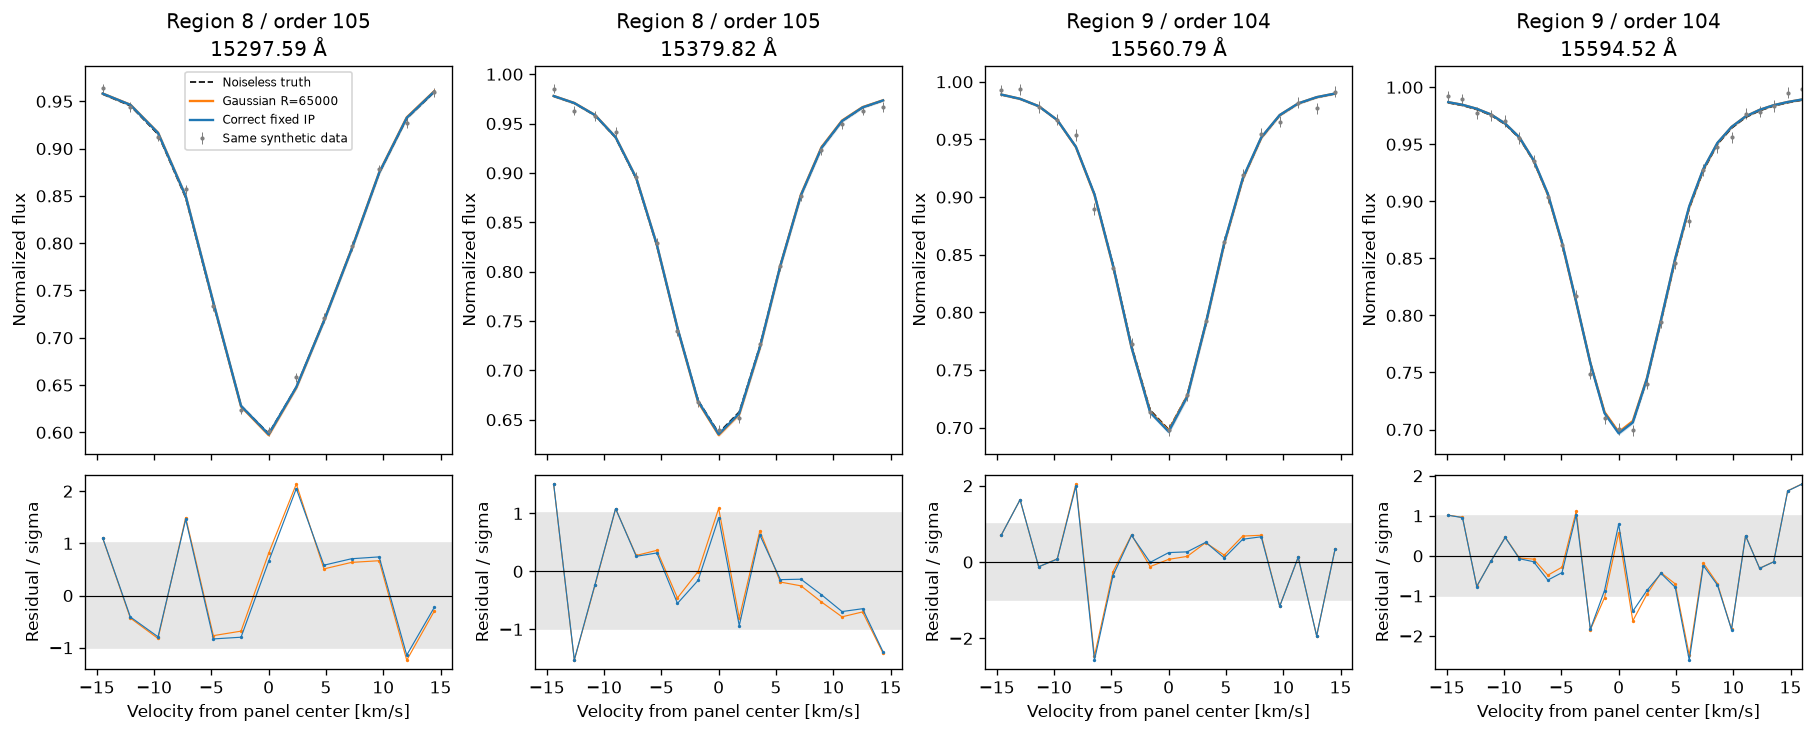

,,rms,standardized_rms,noiseless_truth_rms
region,model,,,
8,Gaussian R=65000,0.004945,0.989037,0.000334
9,Gaussian R=65000,0.005001,1.000141,0.000230
8,Correct fixed IP,0.004944,0.988720,0.000272
9,Correct fixed IP,0.005000,0.999923,0.000267


In [14]:
predictions = {name: fit.predict(samples=samples[name], model=models[name],
                                  max_draws=MAX_PREDICT_DRAWS)
               for name, fit in fits.items()}
fig, axes = plt.subplots(2, 4, figsize=(15, 6), sharex="col",
                         gridspec_kw={"height_ratios": [3, 1.5]}, layout="constrained")
for i in range(2):
    for j in range(2):
        column = 2*i + j
        velocity = C_KMS * np.log(wavelength[i] / zoom_centers[i, j])
        keep = np.abs(velocity) <= ZOOM_KMS
        ax, residual = axes[:, column]
        ax.errorbar(velocity[keep], flux_observed[i, keep], yerr=sigma,
                    fmt=".", ms=3, color="0.5", elinewidth=.6, label="Same synthetic data")
        ax.plot(velocity[keep], flux_fixed[i, keep], "k--", lw=1, label="Noiseless truth")
        for name, prediction in predictions.items():
            mean = np.asarray(prediction["mean_flux"])[i]
            quantiles = np.asarray(prediction["continuum_flux_quantiles"])[:, i]
            ax.plot(velocity[keep], mean[keep], color=colors[name], lw=1.4, label=name)
            ax.fill_between(velocity[keep], quantiles[0, keep], quantiles[1, keep],
                            color=colors[name], alpha=.15)
            residual.plot(velocity[keep], (flux_observed[i, keep] - mean[keep])/sigma,
                          ".-", ms=2, lw=.7, color=colors[name])
        ax.set(title=f"Region {regions[i]} / order {ip_orders[i]}\n{zoom_centers[i, j]:.2f} Å",
               ylabel="Normalized flux", xlim=(-ZOOM_KMS, ZOOM_KMS))
        residual.axhline(0, color="black", lw=.7)
        residual.axhspan(-1, 1, color="0.9", zorder=0)
        residual.set(xlabel="Velocity from panel center [km/s]", ylabel="Residual / sigma")
axes[0, 0].legend(fontsize=7)
show_and_save(fig, "fitted_line_zoom.pdf")

residual_records = []
for name, prediction in predictions.items():
    mean = np.asarray(prediction["mean_flux"])
    for i, region in enumerate(regions):
        residual_records.append(dict(model=name, region=region,
            rms=np.sqrt(np.mean((flux_observed[i] - mean[i])**2)),
            standardized_rms=np.sqrt(np.mean(((flux_observed[i] - mean[i])/sigma)**2)),
            noiseless_truth_rms=np.sqrt(np.mean((flux_fixed[i] - mean[i])**2))))
residual_table = pd.DataFrame(residual_records).set_index(["region", "model"])
display(residual_table)
residual_table.to_csv(run_dir / "residual_comparison.csv")

## 10. Diagnostics and interpretation

Compare the magnitude of each offset with its posterior interval, and inspect
the vsini–zeta joint distribution in the corner plot. Even with the correct
IP, one finite-noise realization can give a posterior median different from
truth, especially near
the vsini=0 boundary. This two-fit comparison measures the effect of the IP
assumption for this experiment; repeat noise seeds to study ensemble bias.

The table below flags sampling problems, including divergent iterations.
For divergences, inspect the geometry and consider a higher
`target_accept_prob`; for poor chain mixing, increase warmup/draws or improve
the parameterization. Neither a low residual RMS nor a point estimate alone
demonstrates parameter recovery.

In [15]:
diagnostic_table = pd.DataFrame(sampling_diagnostics).T
diagnostic_table["checks_pass"] = ((diagnostic_table.divergences == 0)
                                   & (diagnostic_table.max_rhat < 1.01)
                                   & (diagnostic_table.min_n_eff > 200))
display(diagnostic_table)
diagnostic_table.to_csv(run_dir / "sampling_diagnostics.csv")
if not diagnostic_table.checks_pass.all():
    print("Inspect traces and increase sampling before interpreting small differences.")
else:
    print("Both runs meet the displayed convergence checks.")
print("Figures, injected data, comparison tables, and both fit bundles:", run_dir)

,elapsed_seconds,divergences,max_rhat,min_n_eff,checks_pass
Gaussian R=65000,39.185300,0.0,1.004278,213.699279,True
Correct fixed IP,26.980438,0.0,1.030750,108.141922,False


Inspect traces and increase sampling before interpreting small differences.
Figures, injected data, comparison tables, and both fit bundles: /Users/k_masuda/Dropbox/repos/jaxstar/examples/specfit/results/ip_comparison/run_q2o_gxwc
